A rough notebook to get to grips with the data and find overall trends. See WindLoadingMiniProject notebook for full analysis (and cleaner code)

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import windrose

from windrose import WindroseAxes

### Explore the data

In [160]:
wdsp_p3 = pd.read_csv('DATA/Wind+Pylon+P3+Deck.csv/chart.N25NRB.DMA.002.Wind Speed.csv', names=["timeIndex", "avg_wdsp", "gust_wdsp"],
                          comment="#")
wdsp_p3['timeIndex'] = pd.to_datetime(wdsp_p3['timeIndex'], format="%m/%d/%Y %H:%M:%S")

wddir_p3 = pd.read_csv('DATA/Wind+Pylon+P3+Deck.csv/chart.N25NRB.DMA.001.Wind Direction.csv', names=["timeIndex", "angle"],
                          comment="#")
wddir_p3['timeIndex'] = pd.to_datetime(wddir_p3['timeIndex'], format="%m/%d/%Y %H:%M:%S")

wddir_p3 = wddir_p3.set_index("timeIndex")
wddir_p3.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 31969 entries, 2025-01-09 08:51:20 to 2025-01-31 13:58:40
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   angle   31969 non-null  float64
dtypes: float64(1)
memory usage: 499.5 KB


In [73]:
wdsp_p3.describe()

,timeIndex,avg_wdsp,gust_wdsp
count,31969,31969.000000,31969.000000
mean,2025-01-20 11:23:58.789452,4.696424,6.554946
min,2025-01-09 08:51:20,0.039200,0.110000
25%,2025-01-14 22:07:21,2.084800,2.970000
50%,2025-01-20 11:23:18,3.999300,5.590000
75%,2025-01-26 00:39:24,6.712800,9.290000
max,2025-01-31 13:58:40,25.118200,31.850000
std,NaN,3.340263,4.579763


Text(0.5, 1.0, 'Eowyn wind speed')

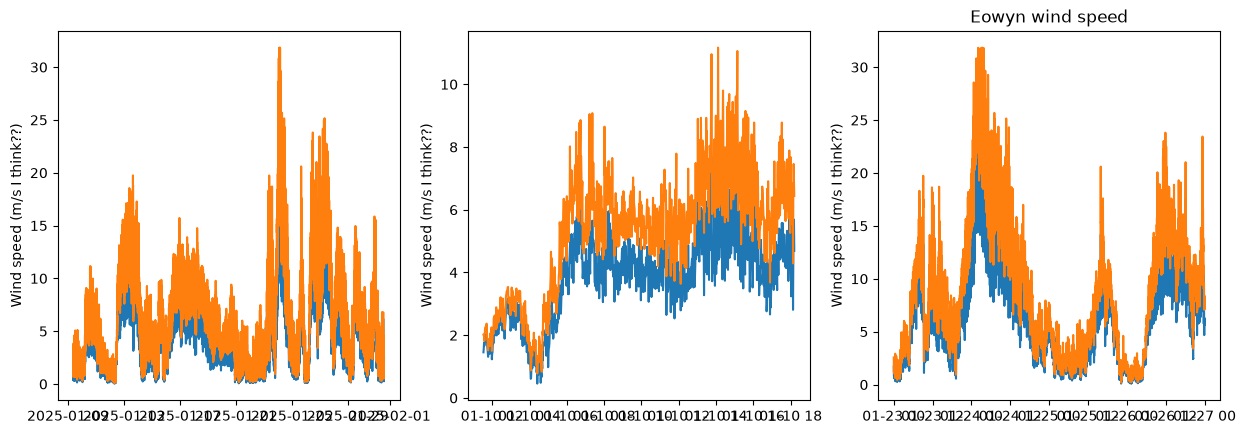

In [130]:
## See if P3 is missing any data
fig, ax = plt.subplots(1,3, figsize=(15, 4.8))

ax[0].plot(wdsp_p3['timeIndex'], wdsp_p3['avg_wdsp'])
ax[0].plot(wdsp_p3['timeIndex'], wdsp_p3['gust_wdsp'])

ax[0].set_ylabel("Wind speed (m/s I think??)")



ax[1].plot(wdsp_p3['timeIndex'].iloc[1000:2000], wdsp_p3['avg_wdsp'].iloc[1000:2000])
ax[1].plot(wdsp_p3['timeIndex'].iloc[1000:2000], wdsp_p3['gust_wdsp'].iloc[1000:2000])

ax[1].set_ylabel("Wind speed (m/s I think??)")


ax[2].plot(eowyn_wdsp_p3['timeIndex'], eowyn_wdsp_p3['avg_wdsp'])
ax[2].plot(eowyn_wdsp_p3['timeIndex'], eowyn_wdsp_p3['gust_wdsp'])

ax[2].set_ylabel("Wind speed (m/s I think??)")
ax[2].set_title('Eowyn wind speed')



Text(0.5, 1.0, 'Wind rose for whole month')

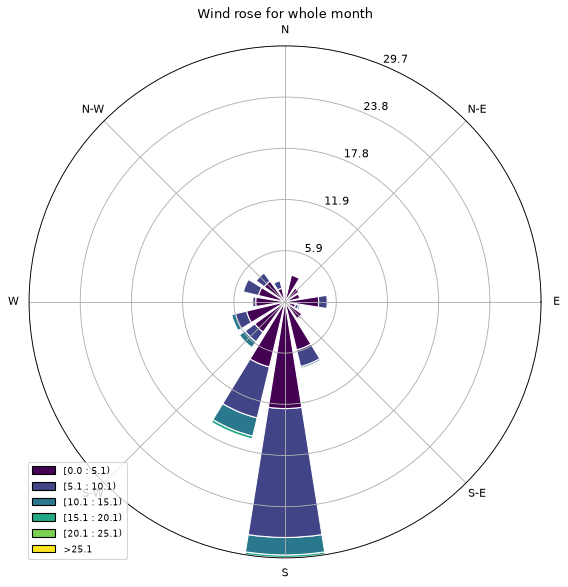

In [125]:
ax = WindroseAxes.from_ax()
ax.bar(wddir_p3['angle'], wdsp_p3['avg_wdsp'], normed=True, opening=0.8, edgecolor="white")
ax.set_legend()
ax.set_title('Wind rose for whole month')

#ax.hlines(0, -50, 50)

Text(0.5, 1.0, 'Wind rose for Eowyn')

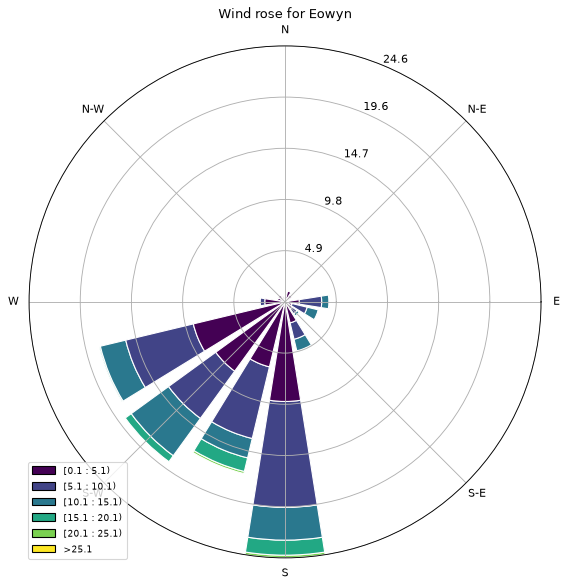

In [129]:
ax = WindroseAxes.from_ax()
ax.bar(eowyn_wddir_p3['angle'], eowyn_wdsp_p3['avg_wdsp'], normed=True, opening=0.8, edgecolor="white")
ax.set_legend()
ax.set_title('Wind rose for Eowyn')

#ax.hlines(0, -50, 50)

Text(0.5, 1.0, 'Gust wind speed distribution')

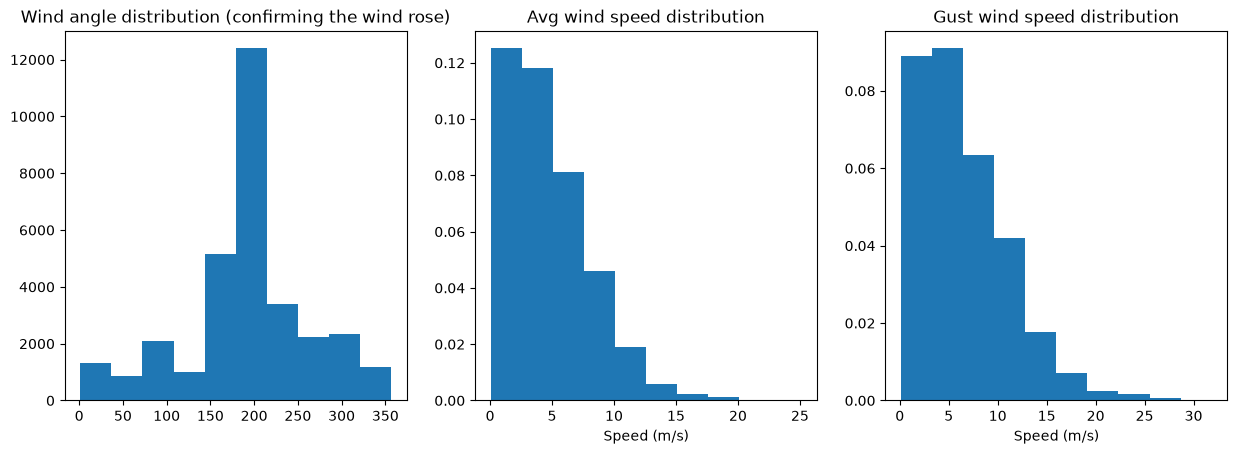

In [103]:
fig, ax = plt.subplots(1,3, figsize = (15, 4.8))

ax[0].hist(wddir_p3['angle'])
ax[0].set_title("Wind angle distribution (confirming the wind rose)")

ax[1].hist(wdsp_p3['avg_wdsp'], density=True)
ax[1].set_xlabel('Speed (m/s)')
ax[1].set_title('Avg wind speed distribution')

ax[2].hist(wdsp_p3['gust_wdsp'], density=True)
ax[2].set_xlabel('Speed (m/s)')
ax[2].set_title('Gust wind speed distribution')

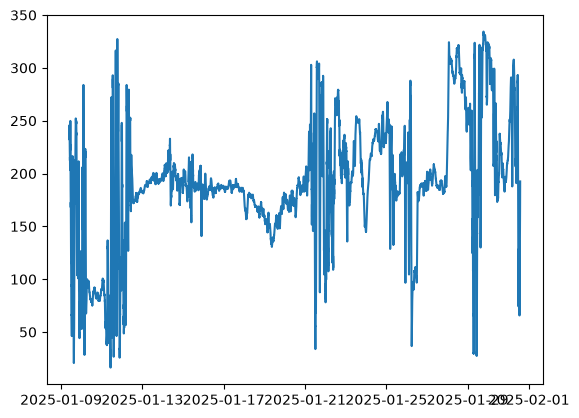

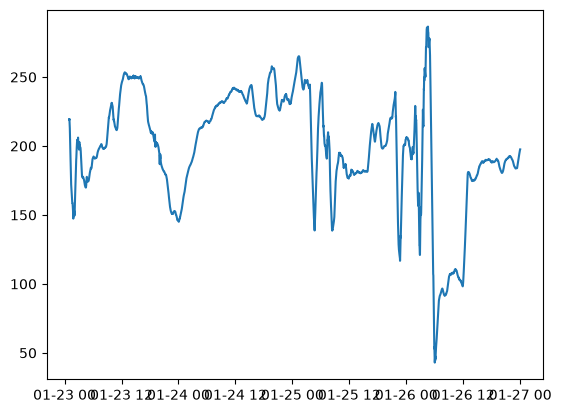

In [164]:
plt.plot(wddir_p3.index, wddir_p3['angle'].rolling(50).mean())

plt.show()

plt.plot(eowyn_wddir_p3.index, eowyn_wddir_p3['angle'].rolling(60).mean())

#plt.vlines([eowyn_wddir_p3.iloc[0]], 0, 350)

In [173]:
# How do I extract a specific date range using teh date time index

#eowyn_range= pd.date_range('24/1/2025 00:00:01', '27/1/2025 23:59:59')
#print(eowyn_range)

eowyn_start = pd.Timestamp('23/1/2025 00:00:01')
eowyn_end = pd.Timestamp('26/1/2025 23:59:59')

print(type(eowyn_start))

eowyn_mask = (wddir_p3.index > eowyn_start) & (wddir_p3.index <= eowyn_end)
eowyn_mask_strain1 = (strain1.index > eowyn_start) & (strain1.index <= eowyn_end)
eowyn_mask_strain1_rollavg = (strain1_rollavg.index > eowyn_start) & (strain1_rollavg.index <= eowyn_end)

eowyn_wddir_p3 = wddir_p3[eowyn_mask]
eowyn_wdsp_p3 = wdsp_p3[eowyn_mask]

eowyn_wddir_p3.head()


print(eowyn_wddir_p3.iloc[0])



#eowyn_index = wddir_p3.index.indexer_between_time('24-1-2025', '27/1/2025 23:59:59')

<class 'pandas.Timestamp'>
angle    230.2667
Name: 2025-01-23 00:00:11, dtype: float64


## Checking out the strain values

Still loads to do on the above, I have a whole to do list done out, but I want to see what this is

In [147]:
# Use the given formula for sideways deflection of the bridge
def deflection_formula(BR, TR, TL, BL):
    return np.abs( ((BR+TR)/2) - ((BL+TL)/2) )

def avg_temp(BR, TR, TL, BL):
    return (BR +TR+TL+BL)/4

In [171]:
strain1 = pd.read_csv('DATA/Strain+at+Section+1+ch.+1+323.50.csv/chart.N25NRB.DMA.001.Strain Readings.csv', 
                      names=["timeIndex", "BR", "TR", "TL", "BL"],
                          comment="#")
strain1['timeIndex'] = pd.to_datetime(strain1['timeIndex'], format="mixed", dayfirst=False)
strain1 = strain1.set_index("timeIndex")



temp1 = pd.read_csv('DATA/Strain+at+Section+1+ch.+1+323.50.csv/chart.N25NRB.DMA.002.Temperature Readings.csv', 
                      names=["timeIndex", "BR", "TR", "TL", "BL"],
                          comment="#")
temp1['timeIndex'] = pd.to_datetime(temp1['timeIndex'], format="mixed", dayfirst=False)
temp1 = temp1.set_index("timeIndex")

strain1_rollavg = strain1.rolling(60).mean()


strain1['deflection'] = deflection_formula(strain1["BR"], strain1["TR"], strain1["BL"], strain1["TL"])
strain1_rollavg['deflection'] = deflection_formula(strain1_rollavg["BR"], strain1_rollavg["TR"], strain1_rollavg["BL"], strain1_rollavg["TL"])

temp1['avg'] = avg_temp(temp1["BR"], temp1["TR"], temp1["BL"], temp1["TL"])

temp1.head()


,BR,TR,TL,BL,avg
timeIndex,,,,,
2025-01-01 08:50:23,9.842,9.382,8.631,9.956,9.45275
2025-01-01 08:51:28,9.911,9.225,8.857,9.478,9.36775
2025-01-01 08:52:32,9.949,9.379,8.261,9.417,9.25150
2025-01-01 08:53:37,9.506,9.355,8.996,9.632,9.37225
2025-01-01 08:54:42,9.908,9.541,8.893,9.577,9.47975


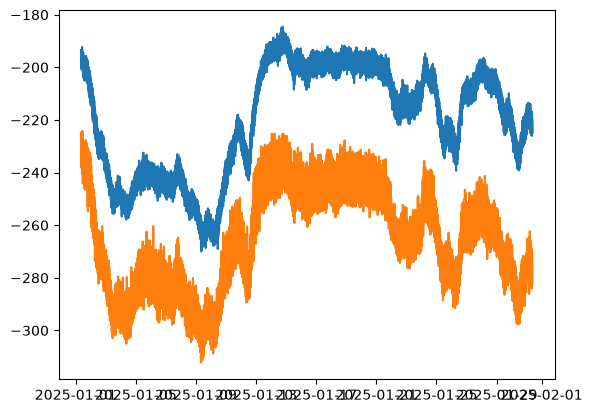

In [143]:
plt.plot(strain1.index, (strain1["BR"]+ strain1["TR"])/2)
plt.plot(strain1.index, (strain1["BL"]+ strain1["TL"])/2)

#plt.plot(strain1.index, strain1["BL"])
#plt.plot(strain1.index, strain1["TR"])
#plt.plot(strain1.index, strain1["TL"])

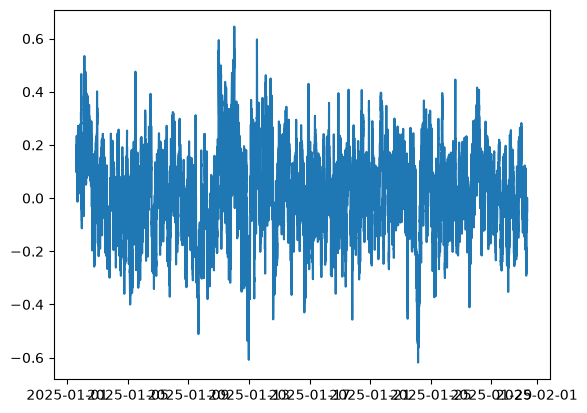

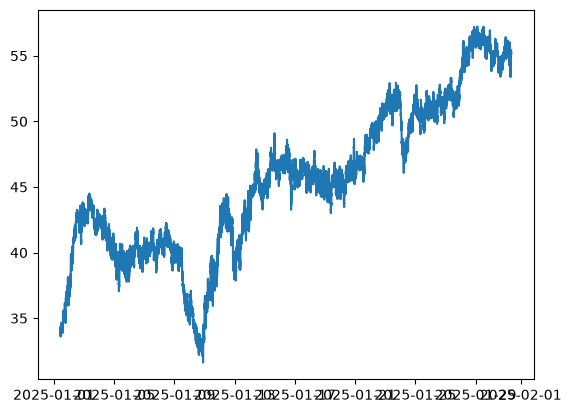

In [172]:
plt.plot(strain1.index, (strain1.deflection - strain1.deflection.rolling(60).mean()).rolling(240).mean())
#plt.plot(temp1.index, temp1.avg.rolling(1).mean())
plt.show()

plt.plot(strain1_rollavg.index, strain1_rollavg.deflection)

# To try: subtract the rollign mean, find a mean value over a calm period and subtrct that (not a perfect solution)

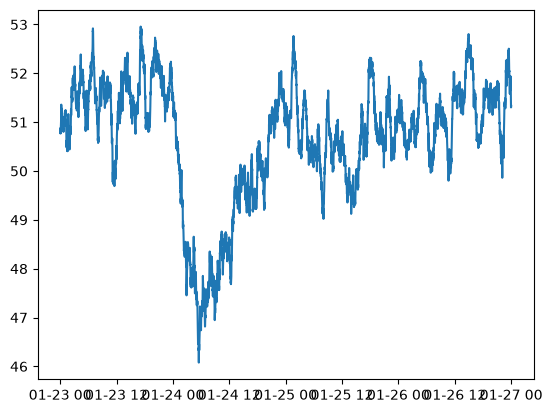

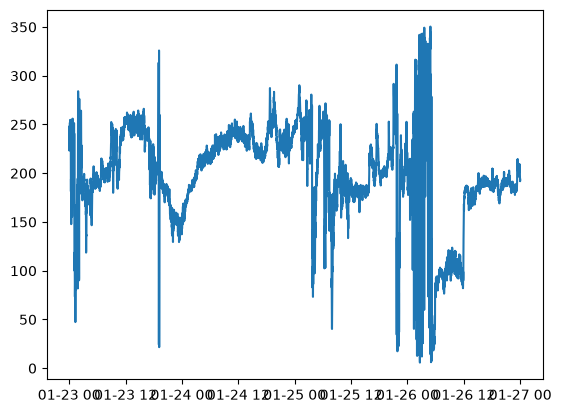

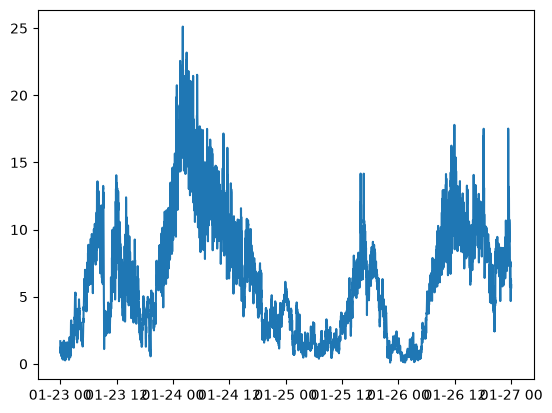

In [180]:

plt.plot(strain1_rollavg[eowyn_mask_strain1_rollavg].index, strain1_rollavg[eowyn_mask_strain1_rollavg].deflection)
plt.show()

plt.plot(eowyn_wddir_p3.index, eowyn_wddir_p3['angle'])#.rolling(60).mean())
plt.show()

plt.plot(eowyn_wdsp_p3['timeIndex'], eowyn_wdsp_p3['avg_wdsp'])#.rolling(60).mean())
#ax[2].plot(eowyn_wdsp_p3['timeIndex'], eowyn_wdsp_p3['gust_wdsp'])

#ax[2].set_ylabel("Wind speed (m/s I think??)")
#ax[2].set_title('Eowyn wind speed')



